# 04 — Model Evaluation: Frozen ResNet-18 + Logistic Regression

This notebook evaluates the baseline outputs created in Notebook 03. It does not train a model and it does not read the official MURA validation split. All results here are **internal development-validation results**.

## What this notebook does

- loads the saved study-level validation predictions from Notebook 03
- calculates AUROC and AUPRC
- selects operating thresholds on internal validation only
- reports sensitivity, specificity, precision, F1, false positives, and false negatives
- saves plots, a bootstrap confidence-interval table, and error tables

The main operating policy is sensitivity ≥ 90%, because missing an abnormal study is an important risk for this project.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    roc_auc_score,
    roc_curve,
)

SEED = 42
BOOTSTRAP_ITERATIONS = 1000
PRIMARY_SENSITIVITY_TARGET = 0.90


## Connect Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Change only this path if your Drive layout is different.

# NOTE: Google Drive files are located inside '/content/drive/MyDrive/' or '/content/drive/Shareddrives/'
DATA_DIR = Path('/content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA')
MODEL_DIR = DATA_DIR / 'BASELINE_MODEL_A'
OUTPUT_DIR = MODEL_DIR / 'internal_validation_evaluation'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = MODEL_DIR / 'validation_predictions.csv'
RANKING_METRICS_PATH = MODEL_DIR / 'validation_ranking_metrics.json'
SELECTION_PATH = MODEL_DIR / 'model_selection.json'
RUN_METADATA_PATH = MODEL_DIR / 'run_metadata.json'
CANDIDATES_PATH = MODEL_DIR / 'logistic_regression_candidates.csv'

for required_path in (
    PREDICTIONS_PATH,
    RANKING_METRICS_PATH,
    SELECTION_PATH,
    RUN_METADATA_PATH,
    CANDIDATES_PATH,
):
    assert required_path.exists(), f'Notebook 03 output not found: {required_path}'

print('Model outputs:', MODEL_DIR)
print('Evaluation outputs:', OUTPUT_DIR)

Model outputs: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A
Evaluation outputs: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation


## Load and validate the saved baseline predictions

The checks below make sure this notebook is evaluating the intended development-validation output and not an official test file.

In [ ]:
validation_predictions = pd.read_csv(PREDICTIONS_PATH)
saved_ranking_metrics = json.loads(RANKING_METRICS_PATH.read_text(encoding='utf-8'))
model_selection = json.loads(SELECTION_PATH.read_text(encoding='utf-8'))
run_metadata = json.loads(RUN_METADATA_PATH.read_text(encoding='utf-8'))
candidate_results = pd.read_csv(CANDIDATES_PATH)

required_columns = {
    'split', 'patient_id', 'study_id', 'label', 'num_views', 'abnormal_probability'
}
missing = required_columns - set(validation_predictions.columns)
assert not missing, f'Missing columns: {sorted(missing)}'
assert validation_predictions['split'].eq('validation').all()
assert validation_predictions['study_id'].is_unique
assert validation_predictions['label'].isin([0, 1]).all()
assert validation_predictions['num_views'].ge(1).all()
assert validation_predictions['abnormal_probability'].between(0, 1).all()
assert model_selection['selection_split'] == 'internal_validation'
assert run_metadata['study_pooling'] == 'mean_embedding'
assert run_metadata['official_mura_valid_read'] is False

print('Guardrail check passed: official MURA valid/test was not read by Notebook 03.')
display(pd.DataFrame([
    {
        'validation_studies': len(validation_predictions),
        'validation_patients': validation_predictions['patient_id'].nunique(),
        'normal_studies': int((validation_predictions['label'] == 0).sum()),
        'abnormal_studies': int((validation_predictions['label'] == 1).sum()),
        'selected_logistic_C': model_selection['selected_c'],
    }
]))
display(candidate_results)

Guardrail check passed: official MURA valid/test was not read by Notebook 03.


,validation_studies,validation_patients,normal_studies,abnormal_studies,selected_logistic_C
0,691,653,422,269,0.01


,C,validation_auroc,validation_auprc
0,0.010,0.888115,0.857160
1,0.100,0.880442,0.851514
2,0.001,0.880098,0.845688
3,1.000,0.867959,0.838195
4,10.000,0.862374,0.831643


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Note: To fully incorporate C=0.01 and C=0.001, you would run Notebook 03
# with candidate_c_values = [0.001, 0.01, 0.1, 1.0, 10.0].
#
# Below is a helper template showing how you can evaluate these additional C values:
print("To try C=0.01 and C=0.001, update the candidate list in Notebook 03:")
print("candidate_c_values = [0.001, 0.01, 0.1, 1.0, 10.0]")


To try C=0.01 and C=0.001, update the candidate list in Notebook 03:
candidate_c_values = [0.001, 0.01, 0.1, 1.0, 10.0]


In [ ]:
summary_df.to_csv('finel_parameters_table.csv', index=False)
print("Saved summary table to 'finel_parameters_table.csv'")

Saved summary table to 'finel_parameters_table.csv'


## Ranking metrics

AUROC and AUPRC describe how well the model ranks studies. They do not depend on one chosen decision threshold.

In [ ]:
y_true = validation_predictions['label'].to_numpy(dtype=int)
y_score = validation_predictions['abnormal_probability'].to_numpy(dtype=float)

ranking_metrics = {
    'split': 'internal_validation',
    'auroc': float(roc_auc_score(y_true, y_score)),
    'auprc': float(average_precision_score(y_true, y_score)),
}

assert np.isclose(ranking_metrics['auroc'], saved_ranking_metrics['auroc'])
assert np.isclose(ranking_metrics['auprc'], saved_ranking_metrics['auprc'])

display(pd.DataFrame([ranking_metrics]))

,split,auroc,auprc
0,internal_validation,0.888115,0.85716


## Threshold policies

Three policies are reported on the internal validation set:

1. **0.50 reference** — a simple fixed reference.
2. **Youden J** — a development diagnostic that balances sensitivity and specificity.
3. **Sensitivity ≥ 90%** — the primary high-sensitivity policy. We choose the highest threshold that still reaches the target sensitivity, which preserves as much specificity as possible on this validation set.

Threshold selection and reporting use the same development validation split here, so these are not final untouched-test results.

In [ ]:
def classification_metrics(y_true, probabilities, threshold):
    predicted_abnormal = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, predicted_abnormal, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan

    return {
        'threshold': float(threshold),
        'sensitivity': float(sensitivity),
        'specificity': float(specificity),
        'precision': float(precision_score(y_true, predicted_abnormal, zero_division=0)),
        'f1': float(f1_score(y_true, predicted_abnormal, zero_division=0)),
        'false_negative_rate': float(1 - sensitivity),
        'true_negative': int(tn),
        'false_positive': int(fp),
        'false_negative': int(fn),
        'true_positive': int(tp),
        'flagged_abnormal': int(predicted_abnormal.sum()),
        'flagged_percent': float(100 * predicted_abnormal.mean()),
    }


def threshold_table(y_true, probabilities):
    rows = []
    candidate_thresholds = np.unique(np.append(probabilities, 0.50))[::-1]
    for threshold in candidate_thresholds:
        row = classification_metrics(y_true, probabilities, threshold)
        row['youden_j'] = row['sensitivity'] + row['specificity'] - 1
        rows.append(row)

    return pd.DataFrame(rows)


def select_high_sensitivity_policy(table, target):
    eligible = table.loc[table['sensitivity'] >= target].copy()
    if eligible.empty:
        raise RuntimeError(f'No threshold reached sensitivity >= {target:.2f}.')

    return eligible.sort_values(
        ['threshold', 'specificity'], ascending=[False, False]
    ).iloc[0].to_dict()


In [ ]:
all_thresholds = threshold_table(y_true, y_score)

reference_policy = classification_metrics(y_true, y_score, threshold=0.50)
youden_policy = all_thresholds.sort_values(
    ['youden_j', 'threshold'], ascending=[False, False]
).iloc[0].to_dict()
primary_policy = select_high_sensitivity_policy(
    all_thresholds, PRIMARY_SENSITIVITY_TARGET
)

policies = [
    ('Reference threshold 0.50', reference_policy, np.nan),
    ('Youden J (development diagnostic)', youden_policy, np.nan),
    (f'Primary: sensitivity >= {PRIMARY_SENSITIVITY_TARGET:.0%}', primary_policy, PRIMARY_SENSITIVITY_TARGET),
]

operating_point_rows = []
for policy_name, values, target in policies:
    row = {'policy': policy_name, 'target_sensitivity': target}
    row.update(values)
    operating_point_rows.append(row)

operating_points = pd.DataFrame(operating_point_rows)
all_thresholds['selected_policy'] = ''
for policy_name, values, _ in policies:
    selected = np.isclose(all_thresholds['threshold'], values['threshold'])
    all_thresholds.loc[selected, 'selected_policy'] = policy_name
display(operating_points)

,policy,target_sensitivity,threshold,sensitivity,specificity,precision,f1,false_negative_rate,true_negative,false_positive,false_negative,true_positive,flagged_abnormal,flagged_percent,youden_j
0,Reference threshold 0.50,NaN,0.500000,0.747212,0.872038,0.788235,0.767176,0.252788,368.0,54.0,68.0,201.0,255.0,36.903039,NaN
1,Youden J (development diagnostic),NaN,0.437779,0.802974,0.836493,0.757895,0.779783,0.197026,353.0,69.0,53.0,216.0,285.0,41.244573,0.639467
2,Primary: sensitivity >= 90%,0.9,0.229778,0.903346,0.580569,0.578571,0.705370,0.096654,245.0,177.0,26.0,243.0,420.0,60.781476,0.483914


## ROC and precision-recall curves

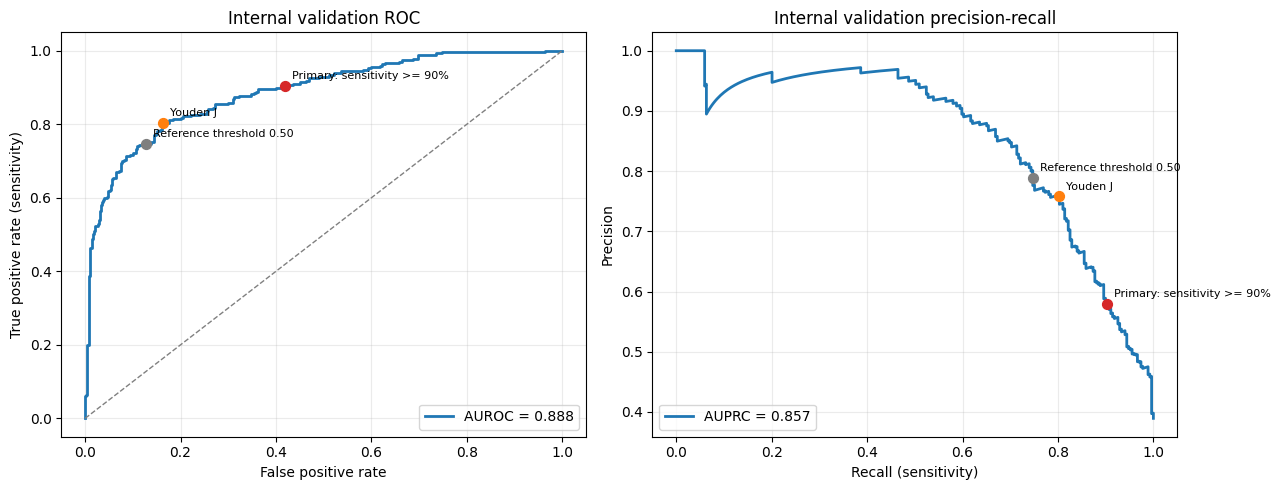

Saved: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation/internal_validation_roc_pr.png


In [ ]:
fpr, tpr, _ = roc_curve(y_true, y_score)
precision, recall, _ = precision_recall_curve(y_true, y_score)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, linewidth=2, label=f"AUROC = {ranking_metrics['auroc']:.3f}")
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate (sensitivity)')
axes[0].set_title('Internal validation ROC')
axes[0].grid(alpha=0.25)

axes[1].plot(recall, precision, linewidth=2, label=f"AUPRC = {ranking_metrics['auprc']:.3f}")
axes[1].set_xlabel('Recall (sensitivity)')
axes[1].set_ylabel('Precision')
axes[1].set_title('Internal validation precision-recall')
axes[1].grid(alpha=0.25)

colors = ['tab:gray', 'tab:orange', 'tab:red']
for axis, x_column, y_column in [
    (axes[0], 'specificity', 'sensitivity'),
    (axes[1], 'sensitivity', 'precision'),
]:
    for (_, row), color in zip(operating_points.iterrows(), colors):
        x_value = 1 - row[x_column] if x_column == 'specificity' else row[x_column]
        axis.scatter(x_value, row[y_column], color=color, s=50, zorder=3)
        axis.annotate(
            row['policy'].replace(' (development diagnostic)', ''),
            (x_value, row[y_column]),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=8,
        )

axes[0].legend(loc='lower right')
axes[1].legend(loc='lower left')
plt.tight_layout()

roc_pr_path = OUTPUT_DIR / 'internal_validation_roc_pr.png'
plt.savefig(roc_pr_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

print('Saved:', roc_pr_path)

## Sensitivity, specificity, and review workload tradeoff

This view shows why the chosen threshold matters: raising sensitivity generally means more studies are flagged for review and lower specificity.

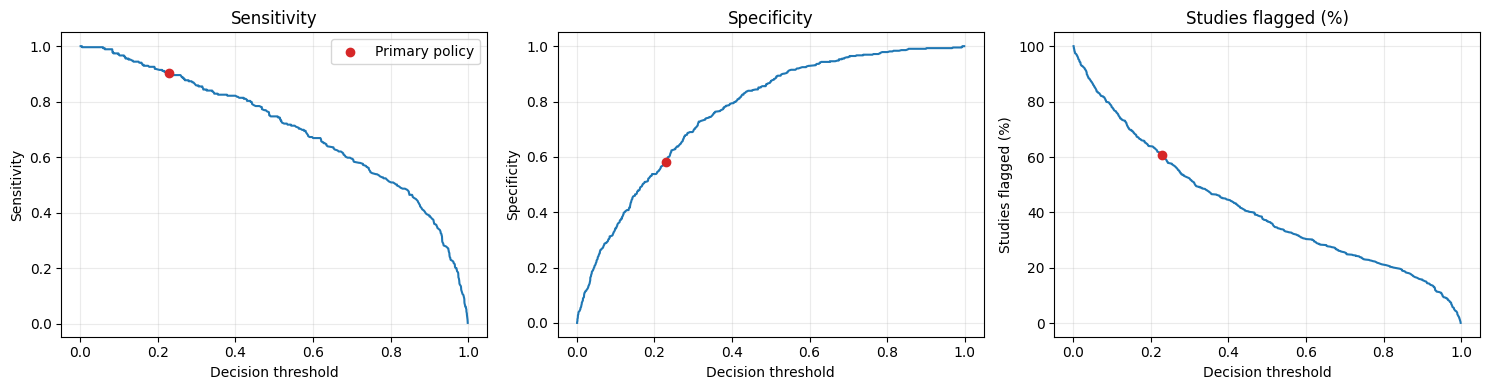

Saved: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation/sensitivity_specificity_workload_tradeoff.png


In [ ]:
tradeoff = all_thresholds.sort_values('threshold')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

charts = [
    ('sensitivity', 'Sensitivity'),
    ('specificity', 'Specificity'),
    ('flagged_percent', 'Studies flagged (%)'),
]

for axis, (column, title) in zip(axes, charts):
    axis.plot(tradeoff['threshold'], tradeoff[column], color='tab:blue')
    axis.scatter(
        primary_policy['threshold'],
        primary_policy[column],
        color='tab:red',
        label='Primary policy',
        zorder=3,
    )
    axis.set_xlabel('Decision threshold')
    axis.set_ylabel(title)
    axis.set_title(title)
    axis.grid(alpha=0.25)

axes[0].legend()
plt.tight_layout()

tradeoff_path = OUTPUT_DIR / 'sensitivity_specificity_workload_tradeoff.png'
plt.savefig(tradeoff_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

print('Saved:', tradeoff_path)

## Confusion matrices

The high-sensitivity policy is the main result for the project. The Youden-J matrix is included only to show the tradeoff.

/tmp/ipykernel_438/4018376778.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


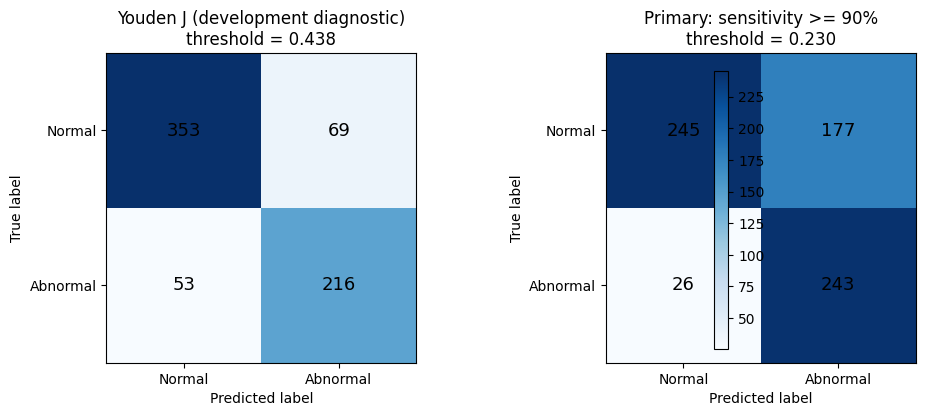

Saved: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation/internal_validation_confusion_matrices.png


In [ ]:
matrix_policies = operating_points.iloc[[1, 2]].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for axis, (_, row) in zip(axes, matrix_policies.iterrows()):
    predicted = (y_score >= row['threshold']).astype(int)
    matrix = confusion_matrix(y_true, predicted, labels=[0, 1])

    image = axis.imshow(matrix, cmap='Blues')
    for r in range(2):
        for c in range(2):
            axis.text(c, r, str(matrix[r, c]), ha='center', va='center', fontsize=13)

    axis.set_xticks([0, 1], labels=['Normal', 'Abnormal'])
    axis.set_yticks([0, 1], labels=['Normal', 'Abnormal'])
    axis.set_xlabel('Predicted label')
    axis.set_ylabel('True label')
    axis.set_title(f"{row['policy']}\nthreshold = {row['threshold']:.3f}")

fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.9)
plt.tight_layout()

confusion_path = OUTPUT_DIR / 'internal_validation_confusion_matrices.png'
plt.savefig(confusion_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

print('Saved:', confusion_path)

## Patient-cluster bootstrap confidence intervals

The bootstrap samples patients rather than individual image views, so all studies belonging to a sampled patient stay together. The selected threshold is treated as fixed here; the interval does not include uncertainty from model or threshold selection.

In [ ]:
def bootstrap_confidence_intervals(frame, threshold, n_iterations, seed):
    patient_ids = frame['patient_id'].astype(str).to_numpy()
    unique_patients = np.unique(patient_ids)
    patient_indices = [np.flatnonzero(patient_ids == patient_id) for patient_id in unique_patients]

    y = frame['label'].to_numpy(dtype=int)
    scores = frame['abnormal_probability'].to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    samples = []

    for _ in range(n_iterations):
        chosen = rng.integers(0, len(unique_patients), size=len(unique_patients))
        indices = np.concatenate([patient_indices[index] for index in chosen])
        bootstrap_y = y[indices]

        if np.unique(bootstrap_y).size < 2:
            continue

        stats = classification_metrics(bootstrap_y, scores[indices], threshold)
        samples.append({
            'auroc': roc_auc_score(bootstrap_y, scores[indices]),
            'auprc': average_precision_score(bootstrap_y, scores[indices]),
            'sensitivity': stats['sensitivity'],
            'specificity': stats['specificity'],
            'precision': stats['precision'],
            'f1': stats['f1'],
        })

    return pd.DataFrame(samples)


primary_threshold = float(operating_points.iloc[2]['threshold'])
bootstrap_samples = bootstrap_confidence_intervals(
    validation_predictions,
    primary_threshold,
    BOOTSTRAP_ITERATIONS,
    SEED,
)
assert len(bootstrap_samples) >= int(BOOTSTRAP_ITERATIONS * 0.95)

point_estimates = {
    'auroc': ranking_metrics['auroc'],
    'auprc': ranking_metrics['auprc'],
    'sensitivity': float(operating_points.iloc[2]['sensitivity']),
    'specificity': float(operating_points.iloc[2]['specificity']),
    'precision': float(operating_points.iloc[2]['precision']),
    'f1': float(operating_points.iloc[2]['f1']),
}

bootstrap_intervals = pd.DataFrame([
    {
        'metric': metric,
        'point_estimate': point_estimates[metric],
        'lower_95_ci': float(bootstrap_samples[metric].quantile(0.025)),
        'upper_95_ci': float(bootstrap_samples[metric].quantile(0.975)),
    }
    for metric in point_estimates
])

display(bootstrap_intervals)
print(f'Valid bootstrap samples: {len(bootstrap_samples)} / {BOOTSTRAP_ITERATIONS}')

,metric,point_estimate,lower_95_ci,upper_95_ci
0,auroc,0.888115,0.862735,0.912071
1,auprc,0.857160,0.817289,0.892637
2,sensitivity,0.903346,0.868603,0.935267
3,specificity,0.580569,0.533325,0.628096
4,precision,0.578571,0.532666,0.628578
5,f1,0.705370,0.666667,0.743281


Valid bootstrap samples: 1000 / 1000


## Error tables for the primary high-sensitivity policy

These tables are for inspection only. MURA labels studies as NORMAL or ABNORMAL; they do not identify a specific acute fracture or lesion.

In [ ]:
primary_predictions = validation_predictions.copy()
primary_predictions['threshold'] = primary_threshold
primary_predictions['predicted_label'] = (
    primary_predictions['abnormal_probability'] >= primary_threshold
).astype(int)
primary_predictions['decision_margin'] = (
    primary_predictions['abnormal_probability'] - primary_threshold
)

false_negatives = primary_predictions.loc[
    (primary_predictions['label'] == 1) & (primary_predictions['predicted_label'] == 0)
].sort_values('abnormal_probability')

false_positives = primary_predictions.loc[
    (primary_predictions['label'] == 0) & (primary_predictions['predicted_label'] == 1)
].sort_values('abnormal_probability', ascending=False)

display(false_negatives.head(10))
display(false_positives.head(10))
print('False negatives:', len(false_negatives))
print('False positives:', len(false_positives))

,split,patient_id,study_id,label,num_views,abnormal_probability,threshold,predicted_label,decision_margin
294,validation,patient07174,patient07174/study1_positive,1,2,0.004173,0.229778,0,-0.225605
154,validation,patient06520,patient06520/study1_positive,1,1,0.058500,0.229778,0,-0.171278
252,validation,patient06982,patient06982/study1_positive,1,4,0.063166,0.229778,0,-0.166612
60,validation,patient03009,patient03009/study1_positive,1,2,0.082211,0.229778,0,-0.147567
121,validation,patient06378,patient06378/study1_positive,1,4,0.082643,0.229778,0,-0.147135
235,validation,patient06904,patient06904/study1_positive,1,2,0.082866,0.229778,0,-0.146912
347,validation,patient07418,patient07418/study1_positive,1,4,0.084786,0.229778,0,-0.144993
203,validation,patient06742,patient06742/study1_positive,1,5,0.098286,0.229778,0,-0.131492
131,validation,patient06416,patient06416/study1_positive,1,3,0.099155,0.229778,0,-0.130623
256,validation,patient06993,patient06993/study1_positive,1,3,0.112279,0.229778,0,-0.117500


,split,patient_id,study_id,label,num_views,abnormal_probability,threshold,predicted_label,decision_margin
670,validation,patient08979,patient08979/study1_negative,0,3,0.993799,0.229778,1,0.764021
603,validation,patient08649,patient08649/study1_negative,0,3,0.992060,0.229778,1,0.762282
451,validation,patient07902,patient07902/study1_negative,0,3,0.967676,0.229778,1,0.737898
437,validation,patient07840,patient07840/study1_negative,0,1,0.900194,0.229778,1,0.670415
438,validation,patient07840,patient07840/study2_negative,0,3,0.853259,0.229778,1,0.623481
362,validation,patient07497,patient07497/study1_negative,0,3,0.848220,0.229778,1,0.618442
682,validation,patient09036,patient09036/study1_negative,0,2,0.830854,0.229778,1,0.601076
66,validation,patient03226,patient03226/study2_negative,0,2,0.813818,0.229778,1,0.584039
674,validation,patient08996,patient08996/study1_negative,0,3,0.801344,0.229778,1,0.571566
651,validation,patient08883,patient08883/study1_negative,0,4,0.783283,0.229778,1,0.553505


False negatives: 26
False positives: 177


## Results by number of views

This is a descriptive check. Small groups should not be interpreted as stable performance estimates.

In [ ]:
def view_group(num_views):
    if num_views == 1:
        return '1 view'
    if num_views == 2:
        return '2 views'
    return '3+ views'


view_rows = []
for group_name, group in primary_predictions.assign(
    view_group=primary_predictions['num_views'].map(view_group)
).groupby('view_group', sort=False):
    group_y = group['label'].to_numpy(dtype=int)
    group_scores = group['abnormal_probability'].to_numpy(dtype=float)
    group_stats = classification_metrics(group_y, group_scores, primary_threshold)

    view_rows.append({
        'view_group': group_name,
        'studies': len(group),
        'abnormal_studies': int((group_y == 1).sum()),
        'normal_studies': int((group_y == 0).sum()),
        'auroc': roc_auc_score(group_y, group_scores) if np.unique(group_y).size == 2 else np.nan,
        'sensitivity': group_stats['sensitivity'],
        'specificity': group_stats['specificity'],
        'note': 'Interpret cautiously' if min((group_y == 1).sum(), (group_y == 0).sum()) < 10 else '',
    })

view_count_summary = pd.DataFrame(view_rows)
display(view_count_summary)

,view_group,studies,abnormal_studies,normal_studies,auroc,sensitivity,specificity,note
0,3+ views,499,222,277,0.875663,0.918919,0.498195,
1,2 views,138,41,97,0.887352,0.829268,0.670103,
2,1 view,54,6,48,0.906250,0.833333,0.875000,Interpret cautiously


## Save evaluation artifacts

In [ ]:
import pandas as pd

# 1. Optimal C from candidate_results
best_c_row = candidate_results.sort_values('validation_auroc', ascending=False).iloc[0]
optimal_c = best_c_row['C']
best_c_auroc = best_c_row['validation_auroc']
best_c_auprc = best_c_row['validation_auprc']

# 2. Optimal Youden J operating point details
optimal_youden_threshold = youden_policy['threshold']
youden_sens = youden_policy['sensitivity']
youden_spec = youden_policy['specificity']
youden_f1 = youden_policy['f1']
youden_j_val = youden_policy['youden_j']

# 3. Create a summary table
summary_data = {
    'Parameter/Metric': [
        'Optimal Regularization (C)',
        'Validation AUROC (at Best C)',
        'Validation AUPRC (at Best C)',
        'Optimal Youden Threshold',
        'Youden Index (J)',
        'Sensitivity (at Youden Threshold)',
        'Specificity (at Youden Threshold)',
        'F1-Score (at Youden Threshold)'
    ],
    'Value': [
        optimal_c,
        best_c_auroc,
        best_c_auprc,
        optimal_youden_threshold,
        youden_j_val,
        youden_sens,
        youden_spec,
        youden_f1
    ]
}

summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Parameter/Metric,Value
0,Optimal Regularization (C),0.010000
1,Validation AUROC (at Best C),0.888115
2,Validation AUPRC (at Best C),0.857160
3,Optimal Youden Threshold,0.437779
4,Youden Index (J),0.639467
5,Sensitivity (at Youden Threshold),0.802974
6,Specificity (at Youden Threshold),0.836493
7,F1-Score (at Youden Threshold),0.779783


In [ ]:
operating_points_path = OUTPUT_DIR / 'operating_points.csv'
threshold_table_path = OUTPUT_DIR / 'threshold_table.csv'
ranking_metrics_path = OUTPUT_DIR / 'validation_ranking_metrics.json'
selected_policy_path = OUTPUT_DIR / 'selected_primary_operating_point.json'
bootstrap_path = OUTPUT_DIR / 'bootstrap_confidence_intervals.csv'
primary_predictions_path = OUTPUT_DIR / 'primary_policy_predictions.csv'
false_negatives_path = OUTPUT_DIR / 'primary_policy_false_negatives.csv'
false_positives_path = OUTPUT_DIR / 'primary_policy_false_positives.csv'
view_count_path = OUTPUT_DIR / 'primary_policy_by_view_count.csv'
config_path = OUTPUT_DIR / 'evaluation_protocol.json'
summary_path = OUTPUT_DIR / 'evaluation_summary.md'
final_parameters_path = OUTPUT_DIR / 'final_parameters_table.csv'

operating_points.to_csv(operating_points_path, index=False)
all_thresholds.to_csv(threshold_table_path, index=False)
ranking_metrics_path.write_text(json.dumps(ranking_metrics, indent=2), encoding='utf-8')
bootstrap_intervals.to_csv(bootstrap_path, index=False)
primary_predictions.to_csv(primary_predictions_path, index=False)
false_negatives.to_csv(false_negatives_path, index=False)
false_positives.to_csv(false_positives_path, index=False)
view_count_summary.to_csv(view_count_path, index=False)
summary_df.to_csv(final_parameters_path, index=False)

primary = operating_points.iloc[2]
selected_primary_policy = {
    key: (int(primary[key]) if key in {'true_negative', 'false_positive', 'false_negative', 'true_positive', 'flagged_abnormal'} else float(primary[key]))
    for key in [
        'threshold', 'sensitivity', 'specificity', 'precision', 'f1', 'false_negative_rate',
        'true_negative', 'false_positive', 'false_negative', 'true_positive',
        'flagged_abnormal', 'flagged_percent',
    ]
}
selected_policy_path.write_text(json.dumps(selected_primary_policy, indent=2), encoding='utf-8')

config_path.write_text(json.dumps({
    'split': 'internal_validation',
    'primary_sensitivity_target': PRIMARY_SENSITIVITY_TARGET,
    'primary_threshold': primary_threshold,
    'threshold_rule': 'highest validation threshold with sensitivity >= target',
    'bootstrap_unit': 'patient cluster',
    'bootstrap_iterations': BOOTSTRAP_ITERATIONS,
    'official_mura_valid_read': False,
}, indent=2), encoding='utf-8')

summary = f"""# Internal validation evaluation — baseline model

This report evaluates the frozen ImageNet ResNet-18 embedding + Logistic Regression baseline using the internal patient-level validation split only. It is a development result, not an untouched final-test result.

## Ranking metrics

- AUROC: {ranking_metrics['auroc']:.6f}
- AUPRC: {ranking_metrics['auprc']:.6f}

## Primary operating policy

The threshold was selected as the highest internal-validation threshold that achieved sensitivity ≥ {PRIMARY_SENSITIVITY_TARGET:.0%}.

- Threshold: {primary['threshold']:.6f}
- Sensitivity: {primary['sensitivity']:.4f}
- Specificity: {primary['specificity']:.4f}
- Precision: {primary['precision']:.4f}
- F1: {primary['f1']:.4f}
- False negatives: {int(primary['false_negative'])}
- False positives: {int(primary['false_positive'])}
- Studies flagged abnormal: {int(primary['flagged_abnormal'])} ({primary['flagged_percent']:.1f}%)

## Important limitation

Model selection, threshold selection, and performance reporting use the same internal validation population in this notebook. The bootstrap intervals treat the threshold as fixed and do not include model-selection or threshold-selection uncertainty. The official MURA validation split was not read.
"""
summary_path.write_text(summary, encoding='utf-8')

for path in [
    operating_points_path, threshold_table_path, ranking_metrics_path, selected_policy_path,
    bootstrap_path, primary_predictions_path,
    false_negatives_path, false_positives_path, view_count_path,
    config_path, summary_path, roc_pr_path, tradeoff_path, confusion_path, final_parameters_path
]:
    print('Saved:', path)

Saved: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation/operating_points.csv
Saved: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation/threshold_table.csv
Saved: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation/validation_ranking_metrics.json
Saved: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation/selected_primary_operating_point.json
Saved: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/internal_validation_evaluation/bootstrap_confidence_intervals.csv
Saved: /content/drive/My

## Result status

The baseline pipeline is now evaluated on the internal validation split. Do not describe these numbers as final official-test results. The next modeling notebook can compare a fine-tuned model fairly against this saved baseline using the same split definitions and study-level metrics.